In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from scipy.stats import pearsonr

pd.set_option('display.max_colwidth', None)

In [2]:
melodies_means = pd.read_csv('data/all_melodies_final_means.csv')

# Built from the MIDI-verified means file (all_melodies_final.csv is a stale, unused duplicate with note-level errors).
stems = {}
for col in melodies_means.columns:
    notes = melodies_means[col].dropna().tolist()
    stems[col] = [int(n) for n in notes[:-1]]

stem_lengths = {name: len(notes) for name, notes in stems.items()}
print(f"{len(stems)} stems, written-stem length range: {min(stem_lengths.values())}-{max(stem_lengths.values())} notes")

90 stems, written-stem length range: 6-9 notes


In [3]:
# Context-sensitivity analysis
rhythms = pd.read_csv('data/all_rhythms.csv')
keys_df = pd.read_csv('data/all_keys.csv')
keys_df['stemID'] = keys_df['stemID'].str.strip()
keys_df['key'] = keys_df['key'].str.strip()
key_map = dict(zip(keys_df['stemID'], keys_df['key']))

pmfm_rhythms = {}
for col in melodies_means.columns:
    rh = rhythms[col].dropna().tolist()
    pmfm_rhythms[col] = [float(v) for v in rh[:-1]]
    assert len(stems[col]) == len(pmfm_rhythms[col]), col

In [4]:
occurrences = []
for n in (2, 3):
    for name, notes in stems.items():
        for start in range(1, len(notes) - n):
            fragment = tuple(notes[start:start + n])
            occurrences.append({
                'occurrence_id': f'{name}@{start}_n{n}',
                'n': n,
                'fragment': fragment,
                'stem': name,
                'start': start,
                'context_notes': tuple(notes[:start]),
                'full_prefix': notes[:start + n],
                'rhythm_prefix': pmfm_rhythms[name][:start + n],
                'key': key_map[name],
                'ground_truth_continuation': notes[start + n],
            })

occurrences_df = pd.DataFrame(occurrences)

groups = defaultdict(list)
for occ in occurrences:
    groups[(occ['n'], occ['fragment'])].append(occ)

pairs = []
for (n, fragment), occs in groups.items():
    for i in range(len(occs)):
        for j in range(i + 1, len(occs)):
            if occs[i]['context_notes'] != occs[j]['context_notes']:
                pairs.append({
                    'n': n,
                    'fragment': fragment,
                    'occurrence_id_a': occs[i]['occurrence_id'],
                    'occurrence_id_b': occs[j]['occurrence_id'],
                    'ground_truth_diff': occs[i]['ground_truth_continuation'] - occs[j]['ground_truth_continuation'],
                })

pairs_df = pd.DataFrame(pairs)
queried_ids = set(pairs_df['occurrence_id_a']) | set(pairs_df['occurrence_id_b'])

print(f"{len(occurrences_df)} total context-having fragment occurrences (n=2: {(occurrences_df['n'] == 2).sum()}, n=3: {(occurrences_df['n'] == 3).sum()})")
print(f"{len(queried_ids)} occurrences belong to a fragment with >=2 differing-context occurrences -- these get queried against PMFM")
print(f"{len(pairs_df)} differing-context pairs formed (n=2: {(pairs_df['n'] == 2).sum()}, n=3: {(pairs_df['n'] == 3).sum()})")

878 total context-having fragment occurrences (n=2: 484, n=3: 394)
414 occurrences belong to a fragment with >=2 differing-context occurrences -- these get queried against PMFM
692 differing-context pairs formed (n=2: 621, n=3: 71)


In [5]:
# Export queries as JSON, consumed by pmfm_fragment_ppd.jl.
query_rows = [occ for occ in occurrences if occ['occurrence_id'] in queried_ids]
with open('data/fragment_context_queries.json', 'w') as f:
    json.dump(query_rows, f)

print(f"Wrote {len(query_rows)} queries to data/fragment_context_queries.json")

Wrote 414 queries to data/fragment_context_queries.json


In [6]:
# Run first: julia --project=MusicalExpectation pmfm_fragment_ppd.jl (produces CSV of predictions).
ppd_results = pd.read_csv('exports/fragment_ppd_results.csv')
occ_results = occurrences_df.merge(ppd_results, on='occurrence_id', how='inner')
print(f"Loaded PMFM PPD results for {len(occ_results)} occurrences")

Loaded PMFM PPD results for 414 occurrences


In [7]:
# Restrict pairs to occurrences with successful PMFM results, and set up for the stabilized/bootstrapped analysis.
results_by_id = occ_results.set_index('occurrence_id')
paired = pairs_df[
    pairs_df['occurrence_id_a'].isin(results_by_id.index) &
    pairs_df['occurrence_id_b'].isin(results_by_id.index)
].copy()

In [8]:
# KL/JS use rounded, Laplace-smoothed particle histograms (note_pmf), matches IDyOM's discrete pitch grid.
import numpy as np
from scipy.stats import entropy
from scipy.spatial.distance import jensenshannon

def note_pmf(samples, support, alpha=0.5):
    rounded = np.round(samples).astype(int)
    counts = np.array([(rounded == note).sum() for note in support], dtype=float)
    counts += alpha
    return counts / counts.sum()

paired['abs_ground_truth_diff'] = paired['ground_truth_diff'].abs()

In [9]:
# IDyOM: PPD already computed at every note position, need to match up with melody renumbering
idyom_dat = pd.read_csv(
    'data/25-cpitch-cpintfref%cpint-22_23_24-nil-melody-nil-1-both-nil-t-nil-c-nil-t-t-x-3.dat',
    sep=' ',
)
idyom_prob_cols = [c for c in idyom_dat.columns if c.startswith('cpitch.') and c.split('.')[1].isdigit()]
idyom_pitches = np.array([int(c.split('.')[1]) for c in idyom_prob_cols])

melody_numbers = pd.read_csv('data/new_melody_numbers.csv')
our_to_dat_name = {
    f"{row['name_original']}{row['number_original']}": f"{row['name_original']}{row['number_encode']:02d}"
    for _, row in melody_numbers.iterrows()
}

idyom_by_melody_note = idyom_dat.set_index(['melody.name', 'note.id'])[idyom_prob_cols]

mismatches = []
for our_name, dat_name in our_to_dat_name.items():
    our_notes = stems[our_name]
    dat_notes = [int(v) for v in idyom_dat[idyom_dat['melody.name'] == dat_name].sort_values('note.id')['cpitch']]
    if dat_notes[:len(our_notes)] != our_notes:
        mismatches.append(our_name)

print(f"{len(our_to_dat_name)} stems mapped to IDyOM melody names, {len(mismatches)} note-content mismatches: {mismatches}")

90 stems mapped to IDyOM melody names, 0 note-content mismatches: []


In [10]:
# note.id = len(full_prefix) + 1 is the position IDyOM predicts right after context+fragment prefix, mirroring what PMFM was fed.
idyom_rows = []
for occ in occurrences:
    dat_name = our_to_dat_name[occ['stem']]
    note_id = len(occ['full_prefix']) + 1
    probs = idyom_by_melody_note.loc[(dat_name, note_id)].values.astype(float)
    true_prob = probs[idyom_pitches == occ['ground_truth_continuation']][0]
    idyom_rows.append({
        'occurrence_id': occ['occurrence_id'],
        'idyom_mean_pred': float(np.sum(idyom_pitches * probs)),
        'idyom_mode_pred': int(idyom_pitches[np.argmax(probs)]),
        'idyom_log_score': float(np.log(true_prob)),
        'idyom_pmf': probs,
    })

idyom_results = pd.DataFrame(idyom_rows)
print(f"Extracted IDyOM PPDs for {len(idyom_results)} occurrences")
idyom_results.drop(columns='idyom_pmf').head()

Extracted IDyOM PPDs for 878 occurrences


,occurrence_id,idyom_mean_pred,idyom_mode_pred,idyom_log_score
0,AC1@1_n2,56.633968,57,-2.501091
1,AC1@2_n2,61.961954,62,-2.058863
2,AC1@3_n2,63.036572,62,-3.106263
3,AC1@4_n2,60.670540,62,-8.638215
4,AC1@5_n2,65.995613,67,-3.017482


In [11]:
# IDyOM's mean/mode/KL/JS diffs for the same pairs.
idyom_by_id = idyom_results.set_index('occurrence_id')

paired['idyom_mean_diff'] = (
    idyom_by_id.loc[paired['occurrence_id_a'], 'idyom_mean_pred'].values -
    idyom_by_id.loc[paired['occurrence_id_b'], 'idyom_mean_pred'].values
)
paired['idyom_mode_diff'] = (
    idyom_by_id.loc[paired['occurrence_id_a'], 'idyom_mode_pred'].values -
    idyom_by_id.loc[paired['occurrence_id_b'], 'idyom_mode_pred'].values
)

idyom_pmf_by_id = dict(zip(idyom_results['occurrence_id'], idyom_results['idyom_pmf']))
idyom_kl_divs, idyom_js_divs = [], []
for _, row in paired.iterrows():
    p = idyom_pmf_by_id[row['occurrence_id_a']]
    q = idyom_pmf_by_id[row['occurrence_id_b']]
    idyom_kl_divs.append(0.5 * entropy(p, q) + 0.5 * entropy(q, p))
    idyom_js_divs.append(jensenshannon(p, q, base=2) ** 2)
paired['idyom_kl_div'] = idyom_kl_divs
paired['idyom_js_div'] = idyom_js_divs

In [12]:
# Stabilize PMFM's stochastic estimates by averaging per-pair metrics across n_runs=10 (see pmfm_fragment_ppd.jl).
multirun = pd.read_csv('exports/fragment_ppd_results_multirun.csv')
n_runs = multirun['run'].nunique()
print(f"{n_runs} runs, {len(multirun)} rows")

mean_diff_runs, mode_diff_runs, kl_div_runs, js_div_runs = [], [], [], []
for r in sorted(multirun['run'].unique()):
    run_df = multirun[multirun['run'] == r].set_index('occurrence_id')
    mean_diff_runs.append(
        run_df.loc[paired['occurrence_id_a'], 'mean_pred'].values -
        run_df.loc[paired['occurrence_id_b'], 'mean_pred'].values
    )
    mode_diff_runs.append(
        run_df.loc[paired['occurrence_id_a'], 'mode_pred'].values -
        run_df.loc[paired['occurrence_id_b'], 'mode_pred'].values
    )
    particles_r = {occ: np.array(json.loads(p)) for occ, p in run_df['particles'].items()}
    kl_r, js_r = [], []
    for _, row in paired.iterrows():
        sa, sb = particles_r[row['occurrence_id_a']], particles_r[row['occurrence_id_b']]
        lo = int(np.floor(min(sa.min(), sb.min())))
        hi = int(np.ceil(max(sa.max(), sb.max())))
        support = range(lo, hi + 1)
        p, q = note_pmf(sa, support), note_pmf(sb, support)
        kl_r.append(0.5 * entropy(p, q) + 0.5 * entropy(q, p))
        js_r.append(jensenshannon(p, q, base=2) ** 2)
    kl_div_runs.append(kl_r)
    js_div_runs.append(js_r)

paired['mean_diff_stable'] = np.mean(mean_diff_runs, axis=0)
paired['mode_diff_stable'] = np.mean(mode_diff_runs, axis=0)
paired['kl_div_stable'] = np.mean(kl_div_runs, axis=0)
paired['js_div_stable'] = np.mean(js_div_runs, axis=0)

10 runs, 4140 rows


In [13]:
# Cluster bootstrap by fragment (pairs sharing a fragment aren't independent) for CIs and p-values.
paired['fragment_key'] = list(zip(paired['n'], paired['fragment']))

def cluster_bootstrap_corr(x, y, cluster_ids, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    groups_idx = pd.DataFrame({'c': cluster_ids}).groupby('c').indices
    clusters = list(groups_idx.keys())
    x, y = np.asarray(x), np.asarray(y)
    boot_rs = np.empty(n_boot)
    for b in range(n_boot):
        sampled = rng.choice(len(clusters), size=len(clusters), replace=True)
        idx = np.concatenate([groups_idx[clusters[k]] for k in sampled])
        boot_rs[b], _ = pearsonr(x[idx], y[idx])
    lo, hi = np.percentile(boot_rs, [2.5, 97.5])
    p = min(2 * min((boot_rs > 0).mean(), (boot_rs < 0).mean()), 1.0)
    return boot_rs.mean(), lo, hi, p

boot_specs = [
    ('PMFM mean-diff', paired['mean_diff_stable'], paired['ground_truth_diff']),
    ('PMFM mode-diff', paired['mode_diff_stable'], paired['ground_truth_diff']),
    ('PMFM KL-div', paired['kl_div_stable'], paired['abs_ground_truth_diff']),
    ('PMFM JS-div', paired['js_div_stable'], paired['abs_ground_truth_diff']),
    ('IDyOM mean-diff', paired['idyom_mean_diff'], paired['ground_truth_diff']),
    ('IDyOM mode-diff', paired['idyom_mode_diff'], paired['ground_truth_diff']),
    ('IDyOM KL-div', paired['idyom_kl_div'], paired['abs_ground_truth_diff']),
    ('IDyOM JS-div', paired['idyom_js_div'], paired['abs_ground_truth_diff']),
]

bootstrap_rows = []
for label, x, y in boot_specs:
    r, lo, hi, p = cluster_bootstrap_corr(x, y, paired['fragment_key'])
    bootstrap_rows.append({'metric': label, 'r': r, 'ci_lo': lo, 'ci_hi': hi, 'p': p})

bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_df

,metric,r,ci_lo,ci_hi,p
0,PMFM mean-diff,0.146808,-0.103036,0.389731,0.266
1,PMFM mode-diff,0.142425,-0.101954,0.381129,0.276
2,PMFM KL-div,0.256408,0.071149,0.431987,0.000
3,PMFM JS-div,0.270034,0.084555,0.440968,0.000
4,IDyOM mean-diff,0.131316,-0.070703,0.328276,0.224
5,IDyOM mode-diff,0.079152,-0.121014,0.261253,0.430
6,IDyOM KL-div,0.022336,-0.079922,0.150349,0.742
7,IDyOM JS-div,0.040412,-0.059310,0.162834,0.468


In [14]:
boot_by_label = bootstrap_df.set_index('metric')

table2_rows = []
for metric_name, pmfm_label, idyom_label in [
    ('mean-diff r vs. ground_truth_diff', 'PMFM mean-diff', 'IDyOM mean-diff'),
    ('mode-diff r vs. ground_truth_diff', 'PMFM mode-diff', 'IDyOM mode-diff'),
    ('KL-div r vs. |ground_truth_diff|', 'PMFM KL-div', 'IDyOM KL-div'),
    ('JS-div r vs. |ground_truth_diff|', 'PMFM JS-div', 'IDyOM JS-div'),
]:
    pr = boot_by_label.loc[pmfm_label]
    ir = boot_by_label.loc[idyom_label]
    table2_rows.append({
        'metric': metric_name,
        'PMFM r': pr['r'], 'PMFM 95% CI': f"[{pr['ci_lo']:.3f}, {pr['ci_hi']:.3f}]", 'PMFM p': pr['p'],
        'IDyOM r': ir['r'], 'IDyOM 95% CI': f"[{ir['ci_lo']:.3f}, {ir['ci_hi']:.3f}]", 'IDyOM p': ir['p'],
    })

table2_df = pd.DataFrame(table2_rows)
table2_df

,metric,PMFM r,PMFM 95% CI,PMFM p,IDyOM r,IDyOM 95% CI,IDyOM p
0,mean-diff r vs. ground_truth_diff,0.146808,"[-0.103, 0.390]",0.266,0.131316,"[-0.071, 0.328]",0.224
1,mode-diff r vs. ground_truth_diff,0.142425,"[-0.102, 0.381]",0.276,0.079152,"[-0.121, 0.261]",0.430
2,KL-div r vs. |ground_truth_diff|,0.256408,"[0.071, 0.432]",0.000,0.022336,"[-0.080, 0.150]",0.742
3,JS-div r vs. |ground_truth_diff|,0.270034,"[0.085, 0.441]",0.000,0.040412,"[-0.059, 0.163]",0.468


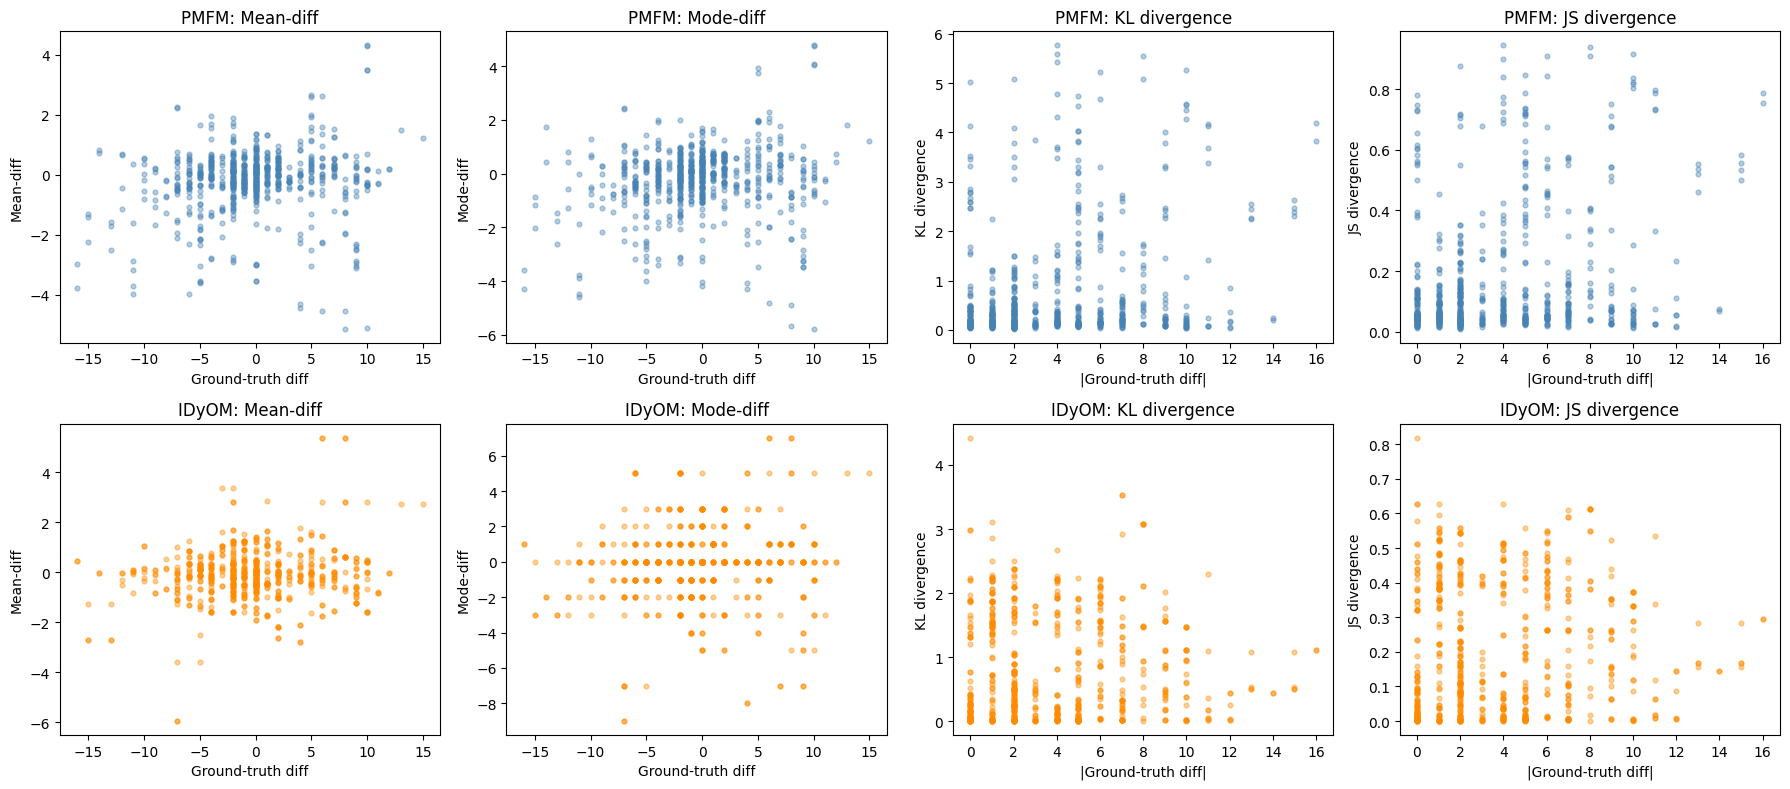

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
row_specs = [
    ('PMFM', 'mean_diff_stable', 'ground_truth_diff', 'Mean-diff'),
    ('PMFM', 'mode_diff_stable', 'ground_truth_diff', 'Mode-diff'),
    ('PMFM', 'kl_div_stable', 'abs_ground_truth_diff', 'KL divergence'),
    ('PMFM', 'js_div_stable', 'abs_ground_truth_diff', 'JS divergence'),
    ('IDyOM', 'idyom_mean_diff', 'ground_truth_diff', 'Mean-diff'),
    ('IDyOM', 'idyom_mode_diff', 'ground_truth_diff', 'Mode-diff'),
    ('IDyOM', 'idyom_kl_div', 'abs_ground_truth_diff', 'KL divergence'),
    ('IDyOM', 'idyom_js_div', 'abs_ground_truth_diff', 'JS divergence'),
]
for i, (model, ycol, xcol, title) in enumerate(row_specs):
    ax = axes[0 if model == 'PMFM' else 1, i % 4]
    color = 'steelblue' if model == 'PMFM' else 'darkorange'
    ax.scatter(paired[xcol], paired[ycol], alpha=0.4, s=12, color=color)
    xlabel = '|Ground-truth diff|' if xcol.startswith('abs') else 'Ground-truth diff'
    ax.set_xlabel(xlabel)
    ax.set_ylabel(title)
    ax.set_title(f'{model}: {title}')

plt.tight_layout()
plt.savefig('plots/context_sensitivity.png', dpi=200)
plt.show()